In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 

warnings.filterwarnings('ignore')

In [57]:
df = pd.read_csv('Admission_Predict.csv')

In [58]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [59]:
df.shape

(400, 9)

In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         400 non-null    int64  
 1   GRE Score          400 non-null    int64  
 2   TOEFL Score        400 non-null    int64  
 3   University Rating  400 non-null    int64  
 4   SOP                400 non-null    float64
 5   LOR                400 non-null    float64
 6   CGPA               400 non-null    float64
 7   Research           400 non-null    int64  
 8   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 28.3 KB


In [61]:
df.duplicated().sum()

np.int64(0)

In [62]:
df.drop(columns='Serial No.', inplace= True)

In [63]:
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


In [64]:
X = df.iloc[:,0:-1]
y = df.iloc[:,-1]

In [65]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    random_state=1,
    test_size= 0.2
)

In [66]:
from sklearn.preprocessing import MinMaxScaler

In [67]:
scaler = MinMaxScaler()

X_train_scaler = scaler.fit_transform(X_train)
X_test_scaler = scaler.transform(X_test)

In [68]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [69]:
model = Sequential()

model.add(Dense(7, activation= 'relu', input_dim = 7))
model.add(Dense(7, activation= 'relu'))
model.add(Dense(1, activation= 'linear'))  # When we work with regration model always use linear activation at the last layer

In [70]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120 (480.00 B)

 Trainable params: 120 (480.00 B)

 Non-trainable params: 0 (0.00 B)

In [71]:
model.compile(loss= 'mean_squared_error', optimizer= 'Adam')

In [72]:
history = model.fit(X_train_scaler, y_train, epochs= 150, validation_split= 0.2)

Epoch 1/150


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.1293 - val_loss: 1.1502
Epoch 2/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.0054 - val_loss: 1.0308
Epoch 3/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9022 - val_loss: 0.9263
Epoch 4/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.8112 - val_loss: 0.8341
Epoch 5/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.7297 - val_loss: 0.7535
Epoch 6/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.6606 - val_loss: 0.6818
Epoch 7/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5982 - val_loss: 0.6191
Epoch 8/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.5438 - val_loss: 0.5629
Epoch 9/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4947 - val_loss: 0.5122
Epoch 10/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4507 - val_loss: 0.4672
Epoch 11/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4109 - val_loss: 0.4255
Epoch 12/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3732 - val_loss: 0.3862
Epoch 13/150

In [73]:
y_pred = model.predict(X_test_scaler)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


In [74]:
from sklearn.metrics import r2_score

In [75]:
r2_score(y_test, y_pred)

0.7726412895570459

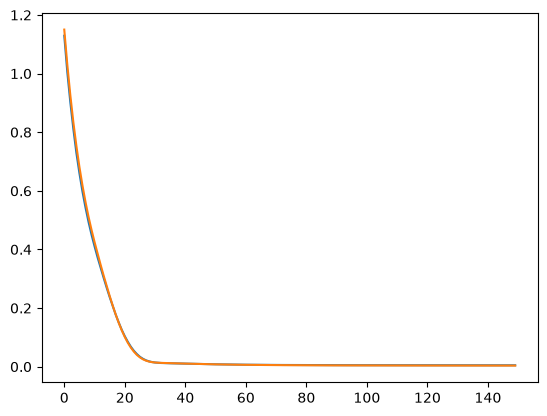

In [76]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])